# Real-data case: does moving the first gate hurt retention in Cookie Cats?

**Context.** *Cookie Cats* is a mobile puzzle game. As players progress they hit **gates** that force them to wait or pay
before continuing. The first gate sat at **level 30**; the team tested moving it to **level 40** to see whether a longer
uninterrupted first session would keep more players around.

This is the same question a product team asks when it moves a paywall, a free-tier limit or an onboarding step:
**where should the first point of friction go so that activation and retention go up, not down?**

| | Definition |
|---|---|
| **Primary metric** | **7-day retention**: share of players who come back 7 days after install (long-term engagement) |
| **Secondary metric** | **1-day retention**: share who come back the next day (activation) |
| **Engagement metric** | `sum_gamerounds`: game rounds played in the first 14 days (heavy-tailed, see section 5) |
| **Hypothesis** | H0: retention(gate 40) = retention(gate 30) · two-sided, α = 0.05 |
| **Randomisation unit** | Player, assigned at install |

| Variant | First gate |
|---|---|
| **A** (control) | Level 30 (`gate_30`) |
| **B** (treatment) | Level 40 (`gate_40`) |

> Unlike the main project, this data is **real**: 90,189 players from the public *Mobile Games A/B Testing with Cookie Cats*
> dataset (DataCamp / Kaggle), mirrored on GitHub. Here the true effect is unknown, so the analysis has to stand on its own.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
import ab_stats as ab

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {"A": "#2a78d6", "B": "#eb6834"}
LABELS = {"A": "A · Gate at level 30", "B": "B · Gate at level 40"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "figure.dpi": 110,
})
pd.set_option("display.float_format", "{:,.4f}".format)

# Source: https://github.com/robguilarr/ab_testing_cookie_cats (datasets/cookie_cats.csv)
df = pd.read_csv(ROOT / "data" / "cookie_cats" / "cookie_cats.csv")
df["variant"] = df["version"].map({"gate_30": "A", "gate_40": "B"})
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7,variant
0,116,gate_30,3,False,False,A
1,337,gate_30,38,True,False,A
2,377,gate_40,165,True,False,B
3,483,gate_40,1,False,False,B
4,488,gate_40,179,True,True,B


## 1. Data quality

One row per player. Before any test: no duplicated players, no missing values and every row maps to a variant.

In [2]:
print(f"Rows: {len(df):,}  |  unique players: {df['userid'].nunique():,}")
print(f"Missing values: {df.isna().sum().sum()}  |  unmapped versions: {df['variant'].isna().sum()}")
print(f"Players who installed but never played a round: {(df['sum_gamerounds'] == 0).mean():.1%}")

Rows: 90,189  |  unique players: 90,189
Missing values: 0  |  unmapped versions: 0
Players who installed but never played a round: 4.4%


## 2. Sanity check: Sample Ratio Mismatch (SRM)

Players should be split 50/50. A chi-square test checks whether the observed split is compatible with that.

In [3]:
counts = df["variant"].value_counts().sort_index()
p_srm = ab.srm_check(counts["A"], counts["B"])
print(counts.to_string())
print(f"\nShare of A: {counts['A'] / counts.sum():.2%}  |  SRM p-value = {p_srm:.4f}")
print("OK: no SRM" if p_srm > 0.001 else "ALERT: possible SRM, check the assignment")

variant
A    44700
B    45489

Share of A: 49.56%  |  SRM p-value = 0.0086
OK: no SRM


The split is 49.6% / 50.4% and the p-value (~0.009) is **above the usual 0.001 alarm threshold**, so the test is not invalidated.
It is low enough to note, though: in a real setting I would ask the game team whether some installs failed to log (e.g. an
app version or platform that only shipped one variant) before final sign-off. The imbalance is 789 players out of 90,189,
far too small to produce the retention gap below on its own.

## 3. Retention: 1-day (activation) and 7-day (primary)

In [4]:
summary = df.groupby("variant").agg(
    players=("userid", "size"),
    retained_1d=("retention_1", "sum"),
    retained_7d=("retention_7", "sum"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean"),
    median_rounds=("sum_gamerounds", "median"),
)
summary

,players,retained_1d,retained_7d,retention_1,retention_7,median_rounds
variant,,,,,,
A,44700,20034,8502,0.4482,0.1902,17.0000
B,45489,20119,8279,0.4423,0.1820,16.0000


In [5]:
tests = {}
for col, name in [("retained_1d", "1-day retention"), ("retained_7d", "7-day retention")]:
    tests[name] = ab.two_proportion_ztest(
        summary.loc["A", col], summary.loc["A", "players"],
        summary.loc["B", col], summary.loc["B", "players"], metric=name,
    )

p_holm = ab.holm_correction([r.p_value for r in tests.values()])
for (name, r), ph in zip(tests.items(), p_holm):
    print(f"{name}:  A {r.value_a:.2%}  ->  B {r.value_b:.2%}")
    print(f"  difference {r.abs_diff * 100:+.2f} pp   95% CI [{r.ci_low * 100:+.2f}, {r.ci_high * 100:+.2f}] pp   "
          f"relative {r.rel_lift:+.1%}")
    print(f"  p-value {r.p_value:.4f}  (Holm-adjusted over the 2 metrics: {ph:.4f})\n")

1-day retention:  A 44.82%  ->  B 44.23%
  difference -0.59 pp   95% CI [-1.24, +0.06] pp   relative -1.3%
  p-value 0.0744  (Holm-adjusted over the 2 metrics: 0.0744)

7-day retention:  A 19.02%  ->  B 18.20%
  difference -0.82 pp   95% CI [-1.33, -0.31] pp   relative -4.3%
  p-value 0.0016  (Holm-adjusted over the 2 metrics: 0.0031)



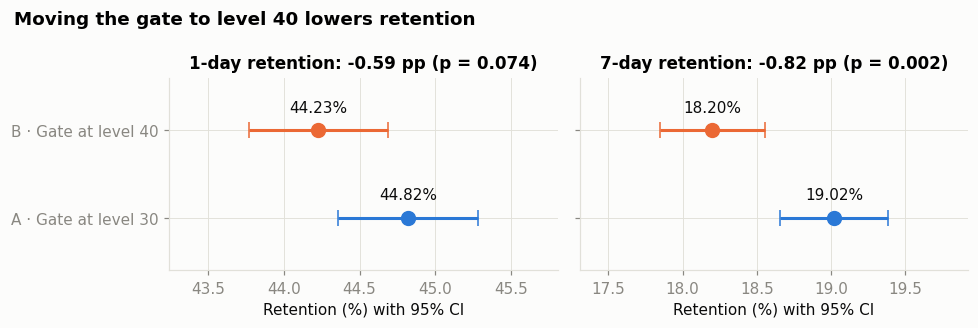

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, (name, r) in zip(axes, tests.items()):
    for i, v in enumerate(["A", "B"]):
        p, n = (r.value_a, summary.loc["A", "players"]) if v == "A" else (r.value_b, summary.loc["B", "players"])
        half = 1.96 * np.sqrt(p * (1 - p) / n)
        ax.errorbar(p * 100, i, xerr=half * 100, fmt="o", color=COLORS[v], ms=9, lw=2, capsize=5)
        ax.annotate(f"{p:.2%}", (p * 100, i), xytext=(0, 12), textcoords="offset points", ha="center", color=INK)
    ax.set_title(f"{name}: {r.abs_diff * 100:+.2f} pp (p = {r.p_value:.3f})", fontsize=11)
    ax.set_xlabel("Retention (%) with 95% CI")
    ax.margins(x=0.35)
axes[0].set_yticks([0, 1], [LABELS["A"], LABELS["B"]])
axes[0].set_ylim(-0.6, 1.6)
fig.suptitle("Moving the gate to level 40 lowers retention", fontweight="bold", x=0.02, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "cookie_cats_retention_ci.png")
plt.show()

- **7-day retention drops by 0.82 pp (19.0% → 18.2%, −4.3% relative)** and the 95% CI is entirely negative. It stays
  significant after correcting for testing two metrics.
- **1-day retention** points the same way (−0.59 pp) but is not significant: the first gate barely matters on day 1,
  because most players have not reached level 30 yet. The damage shows up later, when players would have hit the gate.

## 4. Bayesian view: how sure are we that gate 40 is worse?

The p-value says the data would be unusual if there were no effect. The decision needs something else: **the probability
that gate 40 is better, and how much retention we would lose if we picked it and were wrong** (expected loss).

In [7]:
bayes = {}
for col, name in [("retained_1d", "1-day retention"), ("retained_7d", "7-day retention")]:
    bayes[name] = ab.bayesian_proportions(
        summary.loc["A", col], summary.loc["A", "players"],
        summary.loc["B", col], summary.loc["B", "players"],
    )

pd.DataFrame({
    name: {
        "P(gate 40 > gate 30)": f"{b['prob_b_better']:.2%}",
        "relative lift (95% credible)": f"{b['lift_mean']:+.1%} [{b['lift_ci'][0]:+.1%}, {b['lift_ci'][1]:+.1%}]",
        "expected loss keeping gate 30": f"{b['expected_loss_a'] * 100:.4f} pp",
        "expected loss moving to gate 40": f"{b['expected_loss_b'] * 100:.4f} pp",
    }
    for name, b in bayes.items()
})

,1-day retention,7-day retention
P(gate 40 > gate 30),3.71%,0.08%
relative lift (95% credible),"-1.3% [-2.7%, +0.1%]","-4.3% [-6.9%, -1.7%]"
expected loss keeping gate 30,0.0049 pp,0.0001 pp
expected loss moving to gate 40,0.5965 pp,0.8207 pp


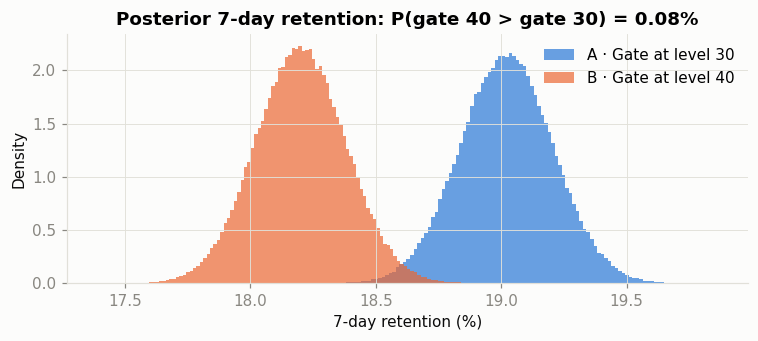

In [8]:
b7 = bayes["7-day retention"]
fig, ax = plt.subplots(figsize=(7, 3.2))
for v in ["A", "B"]:
    ax.hist(b7[f"samples_{v.lower()}"] * 100, bins=120, density=True, color=COLORS[v], alpha=0.7, label=LABELS[v])
ax.set_xlabel("7-day retention (%)")
ax.set_ylabel("Density")
ax.set_title(f"Posterior 7-day retention: P(gate 40 > gate 30) = {b7['prob_b_better']:.2%}")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "cookie_cats_posterior.png")
plt.show()

There is a **~0.1% probability that gate 40 retains better at day 7**. Keeping the gate at 30 has an expected loss of
practically zero, while moving it would cost ~0.8 pp of 7-day retention on average.

## 5. Bootstrap check of the retention difference

Retention is a 0/1 metric, so the z-test's normal approximation is very safe at this sample size. A percentile bootstrap
makes no distributional assumption and should give the same answer; if it did not, that would point to a bug.

In [9]:
a, b = df[df.variant == "A"], df[df.variant == "B"]
lo7, hi7, boot7 = ab.bootstrap_mean_diff(a["retention_7"], b["retention_7"], n_boot=3_000, seed=1)
r7 = tests["7-day retention"]
print(f"7-day retention difference B − A")
print(f"  bootstrap 95% CI: [{lo7 * 100:+.2f}, {hi7 * 100:+.2f}] pp")
print(f"  z-test    95% CI: [{r7.ci_low * 100:+.2f}, {r7.ci_high * 100:+.2f}] pp")
print(f"  share of resamples where gate 40 wins: {(boot7 > 0).mean():.2%}")

7-day retention difference B − A
  bootstrap 95% CI: [-1.32, -0.31] pp
  z-test    95% CI: [-1.33, -0.31] pp
  share of resamples where gate 40 wins: 0.07%


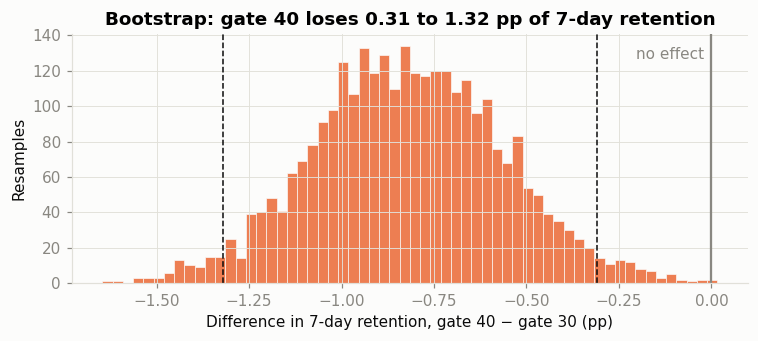

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(boot7 * 100, bins=60, color=COLORS["B"], alpha=0.85, edgecolor="#fcfcfb", linewidth=0.5)
for x in (lo7, hi7):
    ax.axvline(x * 100, color=INK, ls="--", lw=1)
ax.axvline(0, color=MUTED, lw=1.5)
ax.annotate("no effect", (0, ax.get_ylim()[1] * 0.9), xytext=(-5, 0), textcoords="offset points", ha="right", color=MUTED)
ax.set_xlabel("Difference in 7-day retention, gate 40 − gate 30 (pp)")
ax.set_ylabel("Resamples")
ax.set_title(f"Bootstrap: gate 40 loses {-hi7 * 100:.2f} to {-lo7 * 100:.2f} pp of 7-day retention")
fig.tight_layout()
fig.savefig(FIG_DIR / "cookie_cats_bootstrap.png")
plt.show()

Both methods agree to the second decimal.

## 6. Engagement: `sum_gamerounds` is heavy-tailed

Rounds played is the kind of metric that tempts a quick comparison of means. Here that would be misleading.

In [11]:
rounds = df["sum_gamerounds"]
print(rounds.describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(1).to_string())
top = df.loc[rounds.idxmax()]
print(f"\nTop player: {top['sum_gamerounds']:,} rounds in 14 days (variant {top['variant']}); "
      f"next highest: {rounds.nlargest(2).iloc[-1]:,}")

count   90,189.0000
mean        51.9000
std        195.1000
min          0.0000
50%         16.0000
90%        134.0000
99%        493.0000
99.9%    1,073.6000
max     49,854.0000

Top player: 49,854 rounds in 14 days (variant A); next highest: 2,961


In [12]:
def estimators(x):
    x = np.asarray(x)
    return {
        "mean": x.mean(),
        "mean without top player": np.sort(x)[:-1].mean(),
        "5% trimmed mean": stats.trim_mean(x, 0.05),
        "median": np.median(x),
    }

est = pd.DataFrame({v: estimators(g["sum_gamerounds"]) for v, g in df.groupby("variant")})
est["B − A"] = est["B"] - est["A"]
est

,A,B,B − A
mean,52.4563,51.2988,-1.1575
mean without top player,51.3421,51.2419,-0.1002
5% trimmed mean,35.0164,34.8789,-0.1375
median,17.0000,16.0000,-1.0000


**One player with 49,854 rounds** (≈3,500 per day, almost certainly a bot or a logging error; the next highest is 2,961)
**lifts A's mean by 1.1 rounds, which is the entire gap between the two means**. With a standard deviation of ~195 rounds
the mean has a huge standard error and a single row can flip the sign of the result.

The **median** and a **trimmed mean** are robust: they describe the typical player and barely move when extreme values are
added or removed. We compare them with a bootstrap (`ab.bootstrap_stat_diff`), and use a Mann-Whitney U test as a
rank-based check that needs no outlier rule at all.

In [13]:
xa, xb = a["sum_gamerounds"], b["sum_gamerounds"]
rows = []
welch = ab.welch_ttest(xa, xb, metric="mean (Welch)")
rows.append(["mean (Welch t-test)", welch.abs_diff, welch.ci_low, welch.ci_high])
for name, stat in [("5% trimmed mean", lambda x: stats.trim_mean(x, 0.05)), ("median", np.median)]:
    lo, hi, _ = ab.bootstrap_stat_diff(xa, xb, stat, n_boot=2_000, seed=2)
    rows.append([f"{name} (bootstrap)", stat(xb) - stat(xa), lo, hi])
rounds_tests = pd.DataFrame(rows, columns=["estimator", "B − A", "95% CI low", "95% CI high"])
print(f"Mann-Whitney U (B vs A): p = {stats.mannwhitneyu(xb, xa).pvalue:.3f}")
rounds_tests

Mann-Whitney U (B vs A): p = 0.050


,estimator,B − A,95% CI low,95% CI high
0,mean (Welch t-test),-1.1575,-3.7197,1.4047
1,5% trimmed mean (bootstrap),-0.1375,-1.0808,0.7594
2,median (bootstrap),-1.0000,-1.0000,0.0000


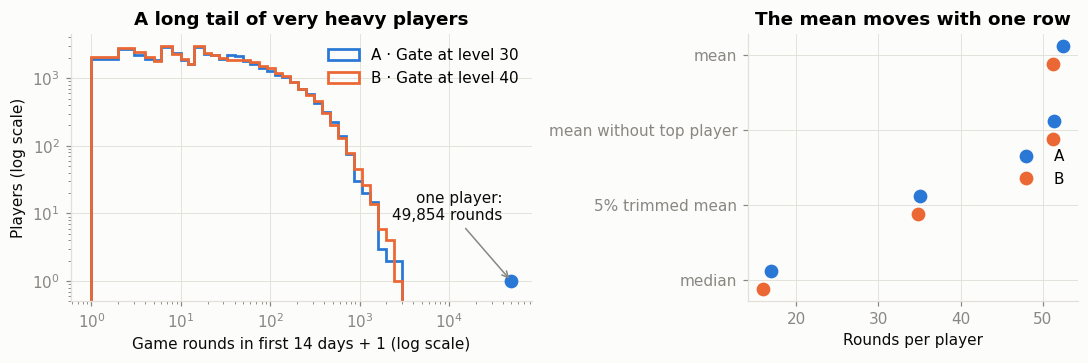

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1.4, 1]})
bins = np.unique(np.round(np.logspace(0, np.log10(rounds.nlargest(2).iloc[-1] + 2), 40)))  # integer edges
for v in ["A", "B"]:
    axes[0].hist(df.loc[df.variant == v, "sum_gamerounds"] + 1, bins=bins, histtype="step", lw=1.8,
                 color=COLORS[v], label=LABELS[v])
axes[0].plot(rounds.max() + 1, 1, "o", color=COLORS[top["variant"]], ms=8)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_ylim(bottom=0.5)
axes[0].set_xlabel("Game rounds in first 14 days + 1 (log scale)")
axes[0].set_ylabel("Players (log scale)")
axes[0].annotate("one player:\n49,854 rounds", (rounds.max() + 1, 1), xytext=(-6, 40), textcoords="offset points",
                 ha="right", color=INK, arrowprops={"arrowstyle": "->", "color": MUTED})
axes[0].legend(frameon=False, loc="upper right")
axes[0].set_title("A long tail of very heavy players")

order = ["mean", "mean without top player", "5% trimmed mean", "median"]
y = np.arange(len(order))[::-1]
for v, dy in [("A", 0.12), ("B", -0.12)]:
    axes[1].plot(est.loc[order, v], y + dy, "o", color=COLORS[v], ms=8, label=v)
axes[1].set_yticks(y, order)
axes[1].set_xlabel("Rounds per player")
axes[1].set_title("The mean moves with one row")
axes[1].legend(frameon=False, loc="center right")
fig.tight_layout()
fig.savefig(FIG_DIR / "cookie_cats_gamerounds.png")
plt.show()

Robust estimators show **no gain in rounds played from gate 40**: the trimmed mean is the same, the median is one round
lower and the Mann-Whitney test is borderline (p ≈ 0.05), if anything pointing to slightly *less* play in B. The raw
difference in means is just the outlier. Engagement does not compensate for the retention loss.

A tempting mistake would be to compare retention only among players who reached level 30. `sum_gamerounds` is measured
**after** assignment and is itself affected by the gate, so filtering on it breaks the randomisation and biases the
comparison. The clean comparison is the one above: all randomised players, intention-to-treat.

## 7. Impact and recommendation

In [15]:
installs = 100_000
lo, hi = r7.ci_low, r7.ci_high
print(f"Per {installs:,} new installs, moving the gate to level 40 would mean "
      f"{-r7.abs_diff * installs:,.0f} fewer players still active on day 7 "
      f"(95% CI: {-hi * installs:,.0f} to {-lo * installs:,.0f}).")

Per 100,000 new installs, moving the gate to level 40 would mean 820 fewer players still active on day 7 (95% CI: 312 to 1,328).


| Question | Answer |
|---|---|
| Is the experiment valid? | Yes: unique players, no missing data, SRM p ≈ 0.009 (above the 0.001 alarm; flagged for a logging check) |
| Does gate 40 change activation (1-day retention)? | Slightly lower (−0.6 pp), not significant |
| Does gate 40 change 7-day retention? | **Yes, lower: −0.82 pp (−4.3%)**, 95% CI [−1.33, −0.31] pp, p = 0.002, Holm-adjusted p = 0.003 |
| What does the Bayesian view say? | P(gate 40 better) ≈ 0.1%; expected loss of keeping gate 30 ≈ 0 |
| Does engagement compensate? | No: median and trimmed-mean rounds are the same; the raw mean difference is one outlier |

**Recommendation: keep the first gate at level 30.** Moving it to level 40 lowers 7-day retention by ~4% with no gain
in engagement: roughly 800 fewer active players on day 7 for every 100,000 installs.

A plausible mechanism is that an earlier break leaves players wanting more (and gives them a reason to come back),
while a later one lets them play until they get bored. That is a hypothesis, not a result of this test.

Caveats and next steps:
1. **Retention is not revenue.** The gate is also a monetisation point; the dataset has no purchases, so the revenue
   impact of the gate position is untested. Before closing the question, check in-app purchase data for the same cohorts.
2. **Long-term retention.** 7 days is the longest horizon available. Day-30 retention would confirm the effect persists.
3. **Explore the other direction.** If an earlier break helps retention, a follow-up test of the gate at level 20 or 25
   (with a pre-registered sample size) is the natural next experiment.